In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../../datasets/heart_final_cleaned.csv")
df = df.dropna().reset_index(drop=True)

X = df.drop("target", axis=1).values.astype(float)
y = df["target"].values.reshape(-1, 1).astype(float)

rng = np.random.default_rng(42)

train_idx, test_idx = [], []

for cls in np.unique(y):
    idx = np.where(y.ravel() == cls)[0]
    rng.shuffle(idx)

    split = int(len(idx) * 0.8)
    train_idx.extend(idx[:split])
    test_idx.extend(idx[split:])

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (241, 13)
Testing Shape: (61, 13)


In [3]:
np.random.seed(42)

input_size = X_train.shape[1]
hidden_size = 32
output_size = 1

W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2 / input_size)
b1 = np.zeros((1, hidden_size))

gamma = np.ones((1, hidden_size))
beta = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * np.sqrt(1 / hidden_size)
b2 = np.zeros((1, output_size))

running_mean = np.zeros((1, hidden_size))
running_var = np.ones((1, hidden_size))

print("Neural Network Initialized")

Neural Network Initialized


In [4]:
def sigmoid(x):
    x = np.clip(x, -20, 20)
    return 1 / (1 + np.exp(-x))


def forward_pass(X, training=True, keep_prob=0.8):

    global running_mean, running_var

    Z1 = X @ W1 + b1

    if training:
        batch_mean = Z1.mean(axis=0, keepdims=True)
        batch_var = Z1.var(axis=0, keepdims=True)

        running_mean = 0.9 * running_mean + 0.1 * batch_mean
        running_var = 0.9 * running_var + 0.1 * batch_var

    else:
        batch_mean = running_mean
        batch_var = running_var

    Z_norm = (Z1 - batch_mean) / np.sqrt(batch_var + 1e-8)
    BN = gamma * Z_norm + beta

    A1 = np.maximum(0, BN)

    if training:
        mask = (np.random.rand(*A1.shape) < keep_prob) / keep_prob
        A1_drop = A1 * mask
    else:
        mask = None
        A1_drop = A1

    Z2 = A1_drop @ W2 + b2
    A2 = sigmoid(Z2)

    cache = (X, Z_norm, batch_var, BN, A1, mask, A1_drop, A2)

    return A2, cache

In [5]:
def backward_pass(y, cache, learning_rate=0.01):

    global W1, b1, W2, b2, gamma, beta

    X, Z_norm, batch_var, BN, A1, mask, A1_drop, A2 = cache

    m = len(y)

    # Output layer gradients
    dZ2 = (A2 - y) / m

    dW2 = A1_drop.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    dA1 = dZ2 @ W2.T

    # Dropout backward pass
    dA1 = dA1 * mask

    # ReLU backward pass
    dBN = dA1 * (BN > 0)

    # Batch Normalization gradients
    dgamma = np.sum(dBN * Z_norm, axis=0, keepdims=True)
    dbeta = np.sum(dBN, axis=0, keepdims=True)

    dZ_norm = dBN * gamma

    inv_std = 1 / np.sqrt(batch_var + 1e-8)

    dZ1 = (inv_std / m) * (
        m * dZ_norm
        - np.sum(dZ_norm, axis=0, keepdims=True)
        - Z_norm * np.sum(dZ_norm * Z_norm, axis=0, keepdims=True)
    )

    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    # Update parameters
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    gamma -= learning_rate * dgamma
    beta -= learning_rate * dbeta

In [6]:
epochs = 100
batch_size = 32
learning_rate = 0.01
keep_prob = 0.8

loss_history = []

for epoch in range(epochs):

    indices = np.random.permutation(len(X_train))
    X_shuffled = X_train[indices]
    y_shuffled = y_train[indices]

    for start in range(0, len(X_train), batch_size):

        end = start + batch_size

        X_batch = X_shuffled[start:end]
        y_batch = y_shuffled[start:end]

        predictions, cache = forward_pass(
            X_batch, training=True, keep_prob=keep_prob
        )

        backward_pass(y_batch, cache, learning_rate)

    # Evaluate training loss without dropout
    train_predictions, _ = forward_pass(
        X_train, training=False
    )

    loss = -np.mean(
        y_train * np.log(train_predictions + 1e-8)
        + (1 - y_train) * np.log(1 - train_predictions + 1e-8)
    )

    loss_history.append(loss)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1}/{epochs} | Loss: {loss:.4f}")

print("Training Completed")

Epoch 10/100 | Loss: 0.5364
Epoch 20/100 | Loss: 0.4826
Epoch 30/100 | Loss: 0.4486
Epoch 40/100 | Loss: 0.4277
Epoch 50/100 | Loss: 0.4101
Epoch 60/100 | Loss: 0.3962
Epoch 70/100 | Loss: 0.3850
Epoch 80/100 | Loss: 0.3779
Epoch 90/100 | Loss: 0.3698
Epoch 100/100 | Loss: 0.3654
Training Completed


In [7]:
test_probabilities, _ = forward_pass(
    X_test, training=False
)

y_pred = (test_probabilities >= 0.5).astype(int)

accuracy = np.mean(y_pred == y_test) * 100

print("Test Accuracy:", round(accuracy, 2), "%")
print("Correct Predictions:", np.sum(y_pred == y_test))
print("Incorrect Predictions:", np.sum(y_pred != y_test))

Test Accuracy: 80.33 %
Correct Predictions: 49
Incorrect Predictions: 12


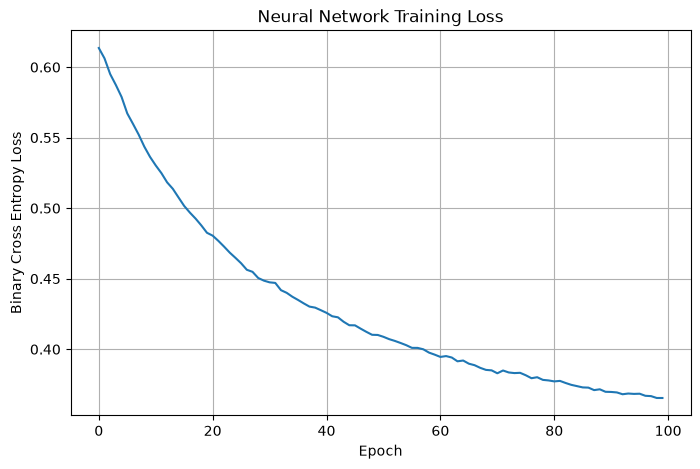

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.title("Neural Network Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross Entropy Loss")

plt.grid()
plt.show()

## Conclusion

In this task, Dropout and Batch Normalization were implemented
from scratch in a neural network.

Dropout randomly deactivated neurons during training to reduce
overfitting, while Batch Normalization stabilized the activations
using batch statistics.

Backpropagation was manually implemented to update weights,
biases, gamma, and beta parameters.

The model was trained using mini-batches and evaluated on
independent test data using classification accuracy.

This implementation demonstrates how Dropout and Batch
Normalization improve neural network training and regularization.